# 비용과 Rate Limit 실습: 문의 셋을 모델 라우터와 예산 가드로 보내고 기준 길이 바꾸기

**이 노트북에서 할 일**

1. 01·03·05절에서 쓴 기능을 책 가게 문의 셋의 흐름 하나로 잇습니다.
2. 기준 길이 30으로 문의 셋을 예약하고 보내, 답과 대화당 비용을 봅니다.
3. 기준 길이 하나만 0으로 바꿔 다시 실행하고, 받은 대화와 포기한 것을 견줍니다.

**준비물** — 이 노트북은 실제 모델에 요청을 다섯 번 보냅니다.
실행 1에서 세 번, 실행 2에서 두 번입니다.
모델별로는 `gpt-5.4-nano`에 두 번, `gpt-5.4-mini`에 세 번입니다.
프로젝트 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
키가 없으면 키를 확인하는 셀에서 멈추고, 모델 요청은 나가지 않습니다.

요청마다 6,000자 정책 글을 앞에 붙여 보내, 요청 하나가 약 3,200토큰입니다.
요금표(2026-09-30 확인)로 어림한 비용은 다섯 번을 합쳐 약 0.006달러입니다.
청구 금액이 아니라, 교재를 만들 때 본 사용량으로 어림한 값입니다.
실행마다 답 글과 토큰 수가 달라질 수 있습니다.
교재를 만들 때 같은 요청 다섯을 노트북 밖에서 다섯 번 더 보내 보았고, 이를 흔들림 확인이라고 부릅니다.

실습 폴더의 도구 파일 `cost_tools.py`에서 함수 아홉을 가져옵니다.
이 노트북은 파일을 쓰지 않습니다.
걸린 시간은 재지 않았습니다.

**기준 버전** — 첫 셀에서 패키지 셋을 설치합니다.
버전은 langchain 1.4.0, langchain-openai 1.6.0, python-dotenv 1.2.3입니다.
셋 모두 실습 폴더 잠금과 같은 버전입니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 버전과 Windows·macOS에서는 실행하지 않았습니다.

**실습 범위** — 이 절은 이 챕터 끝의 실습 절입니다.
강사와 함께 첫 셀부터 차례로 실행하고, 따로 내는 과제는 없습니다.
실습 시간 30분 안팎에 맞춘 분량입니다.

실습 폴더 `labs/part7/ch34-cost-rate-limits`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 조립도입니다. 맨 위 초록 상자 문의 셋 20 25 36글자에서 파란 상자 choose_model 03절 모델 라우터 기준 길이와 글자 수를 견줌으로 갑니다. 이어서 파란 상자 try_reserve 05절 예산 가드 모델마다 예약 금액 비용 상한 0.006으로 갑니다. 여기서 점선 둘이 갈라져, 예약이 막힘은 왼쪽 회색 상자 막힌 대화 요청을 보내지 않음으로, 예약됨은 오른쪽 파란 상자 make_request send_inquiry 01절 실험 번호와 정책 글 6000자를 앞에로 갑니다. 그 아래 보라 상자 gpt-5.4-nano 또는 gpt-5.4-mini temperature=0 reasoning_effort none을 지나, 맨 아래 파란 상자 cost_row total_cost 캐시 입력 할인을 넣은 예상 비용에 이르는 그림](attachment:06-1-세-절의-기능을-이은-조립도.png)

위에서 아래로 읽습니다.
초록 상자는 셀에 적은 문의 셋이고, 파란 상자는 01·03·05절에서 배운 함수입니다.
점선 둘은 예산 가드의 두 갈래입니다.
왼쪽 회색 상자는 막힌 대화가 요청을 보내지 않는다는, 코드 차례로 정해지는 사실입니다.
보라 상자는 이 절에서 실제로 부른 두 모델이고, 맨 아래 상자에서 응답의 사용량으로 대화당 비용을 셉니다.
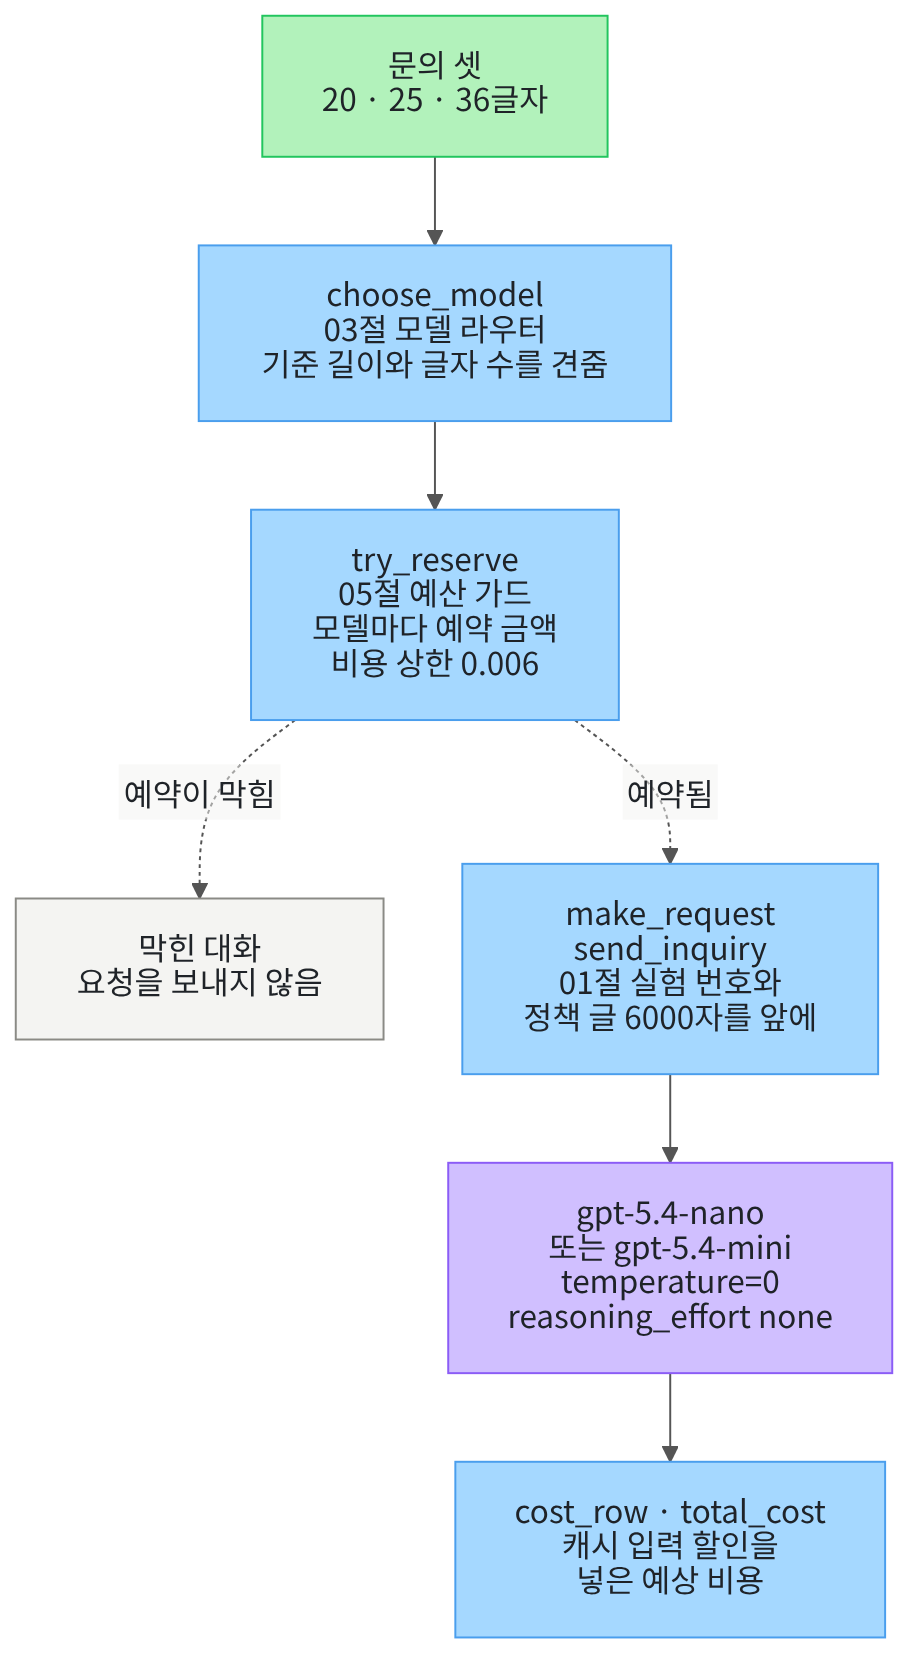

## 1. 준비

이 절은 이 챕터의 실습 절입니다.
01·03·05절에서 쓴 기능을 책 가게 문의 셋의 흐름 하나로 이어 실행합니다.
새 문법과 새 라이브러리 함수는 넣지 않고, 결과를 보는 함수 하나만 이 절에서 만듭니다.

제목의 Rate Limit은 04절에서 본 요청 제한(rate limit)입니다.
이 실습은 요청 제한에 닿는 장면을 만들지 않고, 비용 쪽 기능을 한 흐름으로 잇습니다.

첫 셀은 패키지 셋을 설치하고 설치된 버전을 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.0" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-openai: 1.6.0
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄 `langchain: 1.4.0`과 `langchain-openai: 1.6.0`이 보입니다.
세 패키지 모두 01·03절과 같은 버전입니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
모듈 `uuid`는 01절에서 실험 번호를 만들 때 쓴 모듈입니다.
앞에서 배운 함수 아홉은 도구 파일 `cost_tools.py`에서 가져옵니다.

In [2]:
# 실험 번호를 만들 모듈 uuid와 모델 객체를 만들 함수, 도구 파일의 함수 아홉을 가져옵니다
import uuid
from langchain.chat_models import init_chat_model
# 01·03·05절과 Ch 6 06절·Ch 16 04절에서 배운 함수는 도구 파일에서 가져옵니다(이름의 알파벳 차례)
from cost_tools import choose_model, cost_row, estimate_cost, make_budget, make_request
from cost_tools import make_usage, send_inquiry, total_cost, try_reserve

print("가져온 이름:", "uuid, init_chat_model")
print("도구 파일에서 가져온 함수:", choose_model.__name__, cost_row.__name__, estimate_cost.__name__)
print("도구 파일에서 가져온 함수:", make_budget.__name__, make_request.__name__, make_usage.__name__)
print("도구 파일에서 가져온 함수:", send_inquiry.__name__, total_cost.__name__, try_reserve.__name__)

가져온 이름: uuid, init_chat_model
도구 파일에서 가져온 함수: choose_model cost_row estimate_cost
도구 파일에서 가져온 함수: make_budget make_request make_usage
도구 파일에서 가져온 함수: send_inquiry total_cost try_reserve


**결과 읽기** — 출력 줄 `가져온 이름: uuid, init_chat_model`이 보입니다.
라벨 `도구 파일에서 가져온 함수:` 뒤에 함수 아홉이 세 줄로 나뉘어 보입니다.

함수 `make_request`·`cost_row`는 01절, `choose_model`·`send_inquiry`는 03절에서 배웠습니다.
함수 `make_usage`·`total_cost`·`try_reserve`는 05절에서 배웠습니다.
이 일곱 함수는 이 절에서 도구 파일에 옮겼고, 설명 줄과 본문은 앞 절 셀과 글자까지 같습니다.
나머지 둘 가운데 `estimate_cost`는 Ch 6 06절, `make_budget`은 Ch 16 04절에서 배웠습니다.

앞에서 배운 함수는 `cost_tools.py`에 모아 두었습니다.
파일을 열면 코드를 볼 수 있습니다.
노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.
교재 출력을 만든 실행 도구는 이 폴더를 따로 알려 주어, 다른 자리에서 시작해도 가져오기가 되었습니다.

다음 셀은 `.env` 파일에서 API 키를 읽고, 키가 있는지만 출력합니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


**결과 읽기** — 출력 줄 `OPENAI_API_KEY 설정 여부: True`가 보입니다.
키 값은 출력하지 않고, 있는지만 봅니다.
키가 없으면 이 셀의 `assert`가 멈추고, 뒤 셀의 모델 요청도 나가지 않습니다.

다음 두 셀은 03절과 같은 두 모델을 과정 표준 설정으로 준비합니다.
먼저 작은 모델 `gpt-5.4-nano`입니다.
객체를 만들 때는 모델 요청이 나가지 않습니다.

In [4]:
# 작은 모델 gpt-5.4-nano를 과정 표준 설정으로 준비합니다(요청은 나가지 않습니다)
nano_model = init_chat_model(
    "openai:gpt-5.4-nano",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", nano_model.model_name)
print("temperature:", nano_model.temperature)

모델 이름: gpt-5.4-nano
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-nano`, temperature `0.0`이 보입니다.
03절 노트북의 셀과 글자까지 같은 셀입니다.

다음 셀은 과정 표준 모델 `gpt-5.4-mini`를 같은 설정으로 준비합니다.

In [5]:
# 과정 표준 모델 gpt-5.4-mini를 같은 설정으로 준비합니다(요청은 나가지 않습니다)
mini_model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", mini_model.model_name)
print("temperature:", mini_model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-30에 이 두 모델로 실행한 결과입니다.
온도 값을 0으로 두어도 모델의 답이 매번 같다고 할 수는 없습니다.
인자 `reasoning_effort="none"`은 모델이 답하기 전에 따로 생각하는 단계를 쓰지 않게 합니다.

## 2. 오늘의 상황과 재료

책 가게 상담 서비스에 문의 셋이 차례로 옵니다.
문의마다 긴 정책 글을 앞에 붙여, 모델에 문의의 종류를 묻습니다.
이 절에서는 문의 하나를 대화 하나로 보고, 대화마다 요청을 한 번 보냅니다.
목표는 대화당 비용을 줄이는 것이고, 그 대신 무엇을 포기했는지도 함께 적습니다.

흐름은 네 단계입니다.
03절 모델 라우터가 보낼 모델을 고르고, 05절 예산 가드가 요청 전에 예약합니다.
예약된 대화만 01절처럼 실험 번호와 정책 글을 앞에 붙여 보냅니다.
끝으로 응답의 사용량으로 캐시 입력 할인을 넣은 예상 비용을 셉니다.

다음 셀은 03절과 같은 셀로, 모델 이름과 모델 객체를 딕셔너리에 담습니다.
모델 라우터가 고른 이름으로 모델 객체를 찾을 때 씁니다.

In [6]:
# 모델 라우터가 고른 이름으로 모델 객체를 찾을 수 있게, 이름과 객체를 딕셔너리에 담습니다
models = {"gpt-5.4-nano": nano_model, "gpt-5.4-mini": mini_model}
print("고를 수 있는 모델:", list(models))

고를 수 있는 모델: ['gpt-5.4-nano', 'gpt-5.4-mini']


**결과 읽기** — 출력 줄 `고를 수 있는 모델: ['gpt-5.4-nano', 'gpt-5.4-mini']`가 보입니다.
키는 모델 라우터가 내놓는 이름이고, 값은 1절에서 만든 모델 객체입니다.

다음 셀은 두 모델의 요금표를 적습니다.
값은 03절 셀과 같고, 확인한 날짜만 이 절에서 다시 본 날로 적었습니다.

In [7]:
# 두 모델의 공식 요금(100만 토큰당 달러)과 확인한 날짜를 적고, 모델 이름으로 찾게 모읍니다
pricing_date = "2026-09-30"
nano_prices = {"ordinary_input": 0.20, "cached_input": 0.02, "output": 1.25}
mini_prices = {"ordinary_input": 0.75, "cached_input": 0.075, "output": 4.50}
price_tables = {"gpt-5.4-nano": nano_prices, "gpt-5.4-mini": mini_prices}
print("요금 확인 날짜:", pricing_date)
print("nano 요금:", nano_prices)
print("mini 요금:", mini_prices)

요금 확인 날짜: 2026-09-30
nano 요금: {'ordinary_input': 0.2, 'cached_input': 0.02, 'output': 1.25}
mini 요금: {'ordinary_input': 0.75, 'cached_input': 0.075, 'output': 4.5}


**결과 읽기** — 출력 줄 `요금 확인 날짜: 2026-09-30`이 보입니다.
단위는 100만 토큰당 달러이고, 세 값 모두 nano가 mini보다 작습니다.
두 모델 모두 캐시 입력 요금이 일반 입력 요금의 10분의 1입니다.

다음 셀은 01절과 같은 셀로, 요청마다 똑같이 보낼 긴 정책 글을 만듭니다.
여러 요청이 첫 글자부터 똑같이 보내는 부분을 01절에서는 공통 앞부분이라고 불렀습니다.
이 절에서는 실험 번호와 정책 글이 공통 앞부분이 됩니다.

In [8]:
# 규칙 문장 하나를 100번 이어 붙여, 요청마다 똑같이 보낼 긴 정책 글을 만듭니다
rule_sentence = "고객 문의에 답할 때는 확인한 주문 정보만 근거로 삼고, 확인하지 못한 내용은 확인하지 못했다고 적습니다. "
repeat_count = 100
policy_text = ""
for number in range(repeat_count):
    policy_text = policy_text + rule_sentence
print("규칙 문장의 글자 수:", len(rule_sentence))
print("정책 글의 글자 수:", len(policy_text))

규칙 문장의 글자 수: 60
정책 글의 글자 수: 6000


**결과 읽기** — 출력 줄 `정책 글의 글자 수: 6000`이 보입니다.
규칙 문장 `60`글자를 100번 이어 붙였습니다.
01절에서는 이 정책 글을 앞에 둔 둘째 요청에 캐시 입력이 생겼습니다.

다음 셀은 03절과 같은 셀로, 문의 글 셋과 정답 종류를 같은 차례로 적습니다.
문의마다 맞는 종류를 03절에서는 정답 종류라고 불렀습니다.

In [9]:
# 모델에 보낼 문의 글 셋과, 문의마다 맞는 종류(정답 종류)를 같은 차례로 적습니다
inquiries = [
    "주문한 책이 일주일째 오지 않습니다.",
    "받은 책이 찢어져 있어 돈을 되찾고 싶습니다.",
    "결제 창에서 카드 번호를 넣었는데 다음 단계로 넘어가지 않습니다.",
]
expected_types = ["배송", "환불", "결제"]
print("문의 글 수:", len(inquiries))
print("정답 종류:", expected_types)

문의 글 수: 3
정답 종류: ['배송', '환불', '결제']


**결과 읽기** — 출력 줄 `정답 종류: ['배송', '환불', '결제']`가 보입니다.
세 문의 글은 차례대로 20·25·36글자입니다.
모델 라우터는 이 글자 수만 보고 모델을 고릅니다.

다음 셀은 문의 글 뒤에 붙일 답 형식 글을 정합니다.
03절과 같은 글이고, 03절 함수 `send_inquiry`가 문의 글 뒤에 공백과 함께 붙입니다.

In [10]:
# 문의 글 뒤에 붙일 답 형식 글을 정합니다(03절과 같은 글입니다)
answer_rule = "이 문의의 종류를 배송, 환불, 결제 가운데 한 낱말로 답하세요."
print("답 형식 글:", answer_rule)
print("답 형식 글의 글자 수:", len(answer_rule))

답 형식 글: 이 문의의 종류를 배송, 환불, 결제 가운데 한 낱말로 답하세요.
답 형식 글의 글자 수: 36


**결과 읽기** — 출력 줄 `답 형식 글의 글자 수: 36`이 보입니다.
한 낱말로 답하게 해서, 출력 토큰이 적게 나오게 했습니다.

다음 셀은 대화 하나를 받기 전에 예약할 금액을 모델마다 셉니다.
05절에서는 대화 하나를 받기 전에 예산에 적는 예상 비용을 예약 금액이라고 불렀습니다.
요청 전에는 사용량을 모르므로, 토큰 수를 정해 05절 함수 `make_usage`로 사용량을 만듭니다.
입력 3,200토큰은 01절 교재 출력의 입력 토큰 수보다 조금 크게 정한 값입니다.
캐시 입력은 생길지 모르므로 0으로, 출력은 한 낱말 답이라 넉넉히 20토큰으로 두었습니다.

In [11]:
# 요청 전에 정한 토큰 수로 사용량 딕셔너리를 만들고, 모델마다 대화 하나의 예약 금액을 셉니다
planned_input = 3200
planned_cached = 0
planned_output = 20
planned_usage = make_usage(planned_input, planned_cached, planned_output)
nano_amount = estimate_cost(planned_usage, nano_prices["ordinary_input"], nano_prices["cached_input"], nano_prices["output"])
mini_amount = estimate_cost(planned_usage, mini_prices["ordinary_input"], mini_prices["cached_input"], mini_prices["output"])
amounts = {"gpt-5.4-nano": round(nano_amount, 6), "gpt-5.4-mini": round(mini_amount, 6)}
print("정한 사용량:", planned_usage)
print("모델마다 예약 금액(달러):", amounts)

정한 사용량: {'input_tokens': 3200, 'output_tokens': 20, 'input_token_details': {'cache_read': 0}}
모델마다 예약 금액(달러): {'gpt-5.4-nano': 0.000665, 'gpt-5.4-mini': 0.00249}


**결과 읽기** — 출력 줄 `모델마다 예약 금액(달러): {'gpt-5.4-nano': 0.000665, 'gpt-5.4-mini': 0.00249}`가 보입니다.
모델 nano의 예약 금액은 (3200 × 0.2 + 20 × 1.25) ÷ 1000000 = 0.000665달러입니다.
모델 mini의 예약 금액은 같은 토큰 수에 mini 요금을 곱해 0.00249달러입니다.
두 값은 정한 토큰 수와 요금표로만 정해져, 실행할 때마다 같습니다.

다음 셀은 두 실행에 같게 쓸 비용 상한과 호출 한도를 정합니다.
비용 상한 0.006달러는 실행 전에 이 절에서 정한 값입니다.
모델 nano 둘과 mini 하나의 예약 합은 들어가고, mini 셋의 예약 합은 넘도록 골랐습니다.
이 절은 05절처럼 대화마다 한 번 예약하고, 호출 한도는 대화 수와 같게 둡니다.

In [12]:
# 두 실행에 같게 쓸 비용 상한과 호출 한도를 정합니다(대화 하나에 요청 한 번이라, 호출 한도는 대화 수로 둡니다)
cost_cap = 0.006
max_calls = len(inquiries)
print("비용 상한(달러):", cost_cap)
print("호출 한도:", max_calls)

비용 상한(달러): 0.006
호출 한도: 3


**결과 읽기** — 출력 줄 `비용 상한(달러): 0.006`과 `호출 한도: 3`이 보입니다.
호출 한도가 대화 수와 같아, 이 절에서 호출 한도에 막히는 대화는 없습니다.
막는 일은 05절처럼 비용 상한만 합니다.

Ch 16 04절은 요청마다 예약했고, 05절은 대화마다 예약했습니다.
이 절은 대화 하나에 요청 한 번이라, 예산 칸 `calls`는 받은 대화 수이자 보낸 요청 수가 됩니다.

다음 셀은 결과를 볼 함수를 정의합니다.
응답 하나의 대화 번호·응답한 모델·답·정답 종류와 같은지·토큰 수를 한 줄로 출력합니다.
캐시 입력 토큰 수는 01절에서 본 사용량 칸 `cache_read`의 값입니다.
함수는 답이 정답 종류와 같은지를 내놓아, 뒤 셀에서 같은 답의 수를 셉니다.

In [13]:
# 응답 하나의 대화 번호·응답한 모델·답·정답 종류와 같은가·토큰 수를 한 줄로 출력하고, 정답 종류와 같은지를 내놓습니다
def print_answer(number, response, expected_type):
    usage = response.usage_metadata
    cache_read = usage["input_token_details"]["cache_read"]
    matched = response.text == expected_type
    print(number, "|", response.response_metadata["model_name"], "|", response.text, "|", matched, "|", usage["input_tokens"], "|", cache_read)
    return matched

**결과 읽기** — 정의 셀이라 출력이 없습니다.
응답한 모델의 이름은 03절처럼 `response_metadata`에서 꺼냅니다.
답은 연산자 `==`로 정답 종류와 글자까지 견줍니다.
이 절에서 새로 만드는 함수는 이것 하나입니다.

**가설** — 실행 1은 기준 길이를 30으로 두어, 03절 실행 1처럼 nano·nano·mini로 보냅니다.
예약 합은 0.000665 + 0.000665 + 0.00249 = 0.00382달러라, 셋을 모두 받을 것입니다.
nano 둘째 요청은 같은 번호와 정책 글 뒤에 오므로, 01절처럼 캐시 입력이 생길 것입니다.
대화 3은 그 실행에서 mini로 보내는 첫 요청이라, 캐시 입력이 없을 것입니다.

## 3. 실행 1 — 기준 길이 30

다음 셀은 기준 길이를 30으로 두고, 문의마다 모델 라우터가 고른 이름을 모읍니다.
03절에서 본 대로, 모델 라우터는 Ch 26 03절의 라우터와 달리 모델 이름만 고릅니다.
이 셀에서는 모델 요청이 나가지 않습니다.

In [14]:
# 실행 1: 기준 길이를 30으로 두고, 문의마다 모델 라우터가 고른 이름을 모읍니다(요청 없음)
run1_limit = 30
run1_models = []
for inquiry in inquiries:
    run1_models.append(choose_model(inquiry, run1_limit))
print("기준 길이:", run1_limit)
print("모델 배정:", run1_models)

기준 길이: 30
모델 배정: ['gpt-5.4-nano', 'gpt-5.4-nano', 'gpt-5.4-mini']


**결과 읽기** — 출력 줄 `모델 배정: ['gpt-5.4-nano', 'gpt-5.4-nano', 'gpt-5.4-mini']`이 보입니다.
03절 실행 1과 같은 모델 배정입니다.
36글자인 대화 3만 기준 길이 30보다 길어 mini로 갑니다.

다음 셀은 대화마다 고른 모델의 예약 금액을 예산에 먼저 예약해 봅니다.
05절 함수 `try_reserve`는 예약이 되면 「예약됨」을, 막히면 받은 오류의 글을 내놓습니다.
05절에서는 예약이 된 대화를 받은 대화, 예약이 막힌 대화를 막힌 대화라고 불렀습니다.
이 셀에서도 모델 요청은 나가지 않습니다.

In [15]:
# 실행 1: 대화마다 고른 모델의 예약 금액을 먼저 예약해 봅니다(요청 없음)
run1_budget = make_budget(max_calls, cost_cap)
run1_results = []
for number in range(len(inquiries)):
    model_name = run1_models[number]
    run1_results.append(try_reserve(run1_budget, amounts[model_name]))
print("예약 결과:", run1_results)
print("받은 대화 수:", run1_results.count("예약됨"))
print("예약한 금액의 합(달러):", round(run1_budget["cost_usd"], 6))

예약 결과: ['예약됨', '예약됨', '예약됨']
받은 대화 수: 3
예약한 금액의 합(달러): 0.00382


**결과 읽기** — 출력 줄 `예약 결과: ['예약됨', '예약됨', '예약됨']`과 `받은 대화 수: 3`이 보입니다.
예약한 금액의 합은 `0.00382`달러로, 비용 상한 0.006달러 안입니다.
이 절은 예약 결과를 먼저 모두 만든 뒤, 받은 대화만 보냅니다.
예산은 예약 금액으로만 바뀌어, 대화마다 예약 직후 보내도 받는 대화는 같습니다.

다음 셀은 실행 1에서만 쓸 실험 번호를 만들고, 대화 1로 보낼 요청 글의 모양을 봅니다.
실험 번호는 01절에서, 앞 실행이 남긴 앞부분과 맞지 않게 요청 글 맨 앞에 둔 무작위 글입니다.
실행 2에서는 번호를 새로 만들어, 실행 1이 남긴 앞부분과도 맞지 않게 합니다.

In [16]:
# 실행 1에서만 쓸 실험 번호를 만들고, 대화 1로 보낼 요청 글의 모양을 봅니다(번호는 글자 수만 출력합니다)
run1_mark = "실험 번호 " + uuid.uuid4().hex
first_request = make_request(run1_mark, policy_text, inquiries[0]) + " " + answer_rule
print("실험 번호의 글자 수:", len(run1_mark))
print("요청 글 1의 글자 수:", len(first_request))
print("정책 글이 시작하는 자리:", first_request.find(policy_text))

실험 번호의 글자 수: 38
요청 글 1의 글자 수: 6097
정책 글이 시작하는 자리: 39


**결과 읽기** — 출력 줄 `요청 글 1의 글자 수: 6097`과 `정책 글이 시작하는 자리: 39`가 보입니다.
실험 번호 `38`글자와 줄바꿈 하나 뒤에 정책 글이 시작합니다.
정책 글 뒤에는 줄바꿈, 문의 글, 공백, 답 형식 글이 옵니다.
01절 요청 글 1과 글자 수와 모양이 같고, 실험 번호만 다릅니다.

다음 셀은 받은 대화만 차례로 보냅니다.
함수 `make_request`가 실험 번호·정책 글·문의 글을 줄바꿈으로 잇습니다.
함수 `send_inquiry`는 그 글 뒤에 공백과 답 형식 글을 붙여, 고른 모델로 보냅니다.
이 셀에서 모델 요청이 세 번 나갑니다.

In [17]:
# 실행 1: 예약된 대화만 실험 번호와 정책 글을 앞에 붙여, 고른 모델로 하나씩 보냅니다(모델 요청 3번)
run1_sent = []
run1_responses = []
for number in range(len(inquiries)):
    if run1_results[number] == "예약됨":
        question = make_request(run1_mark, policy_text, inquiries[number])
        run1_responses.append(send_inquiry(question, run1_models[number], models, answer_rule))
        run1_sent.append(number)
print("보낸 요청 수:", len(run1_responses))

보낸 요청 수: 3


**결과 읽기** — 출력 줄 `보낸 요청 수: 3`이 보입니다.
받은 대화 셋을 모두 보냈습니다.

목록 `run1_sent`에는 보낸 대화의 차례 번호를 0부터 세어 담았습니다.

다음 셀은 보낸 대화마다 응답을 한 줄씩 보고, 정답 종류와 같은 답을 셉니다.
각 줄의 마지막 칸이 캐시 입력 토큰 수입니다.

In [18]:
# 실행 1에서 보낸 대화마다 응답을 한 줄씩 보고, 정답 종류와 같은 답을 셉니다(요청 없음)
print("대화 | 응답한 모델 | 답 | 정답 종류와 같은가 | 입력 토큰 | 캐시 입력 토큰")
run1_matched = 0
for index in range(len(run1_sent)):
    number = run1_sent[index]
    matched = print_answer(number + 1, run1_responses[index], expected_types[number])
    if matched:
        run1_matched = run1_matched + 1
print("정답 종류와 같은 답 수:", run1_matched)

대화 | 응답한 모델 | 답 | 정답 종류와 같은가 | 입력 토큰 | 캐시 입력 토큰
1 | gpt-5.4-nano-2026-03-17 | 배송 | True | 3164 | 0
2 | gpt-5.4-nano-2026-03-17 | 환불 | True | 3168 | 2816
3 | gpt-5.4-mini-2026-03-17 | 결제 | True | 3168 | 0
정답 종류와 같은 답 수: 3


**결과 읽기** — 라벨 줄 아래 세 줄에서, 응답한 모델 이름이 모델 배정의 이름으로 시작합니다.
대화 1·2는 `gpt-5.4-nano-2026-03-17`, 대화 3은 `gpt-5.4-mini-2026-03-17`이 답했습니다.
대화 1은 새 실험 번호로 보낸 첫 요청이라, 캐시 입력 토큰 수가 0입니다.
흔들림 확인 다섯 번과 새 커널 두 번에서 모두, 대화 3의 캐시 입력은 0이었고 세 답은 정답 종류와 같았습니다.
대화 3은 그 실행에서 mini로 보낸 첫 요청입니다.

교재 출력에서는 답이 차례대로 `배송`, `환불`, `결제`입니다.
입력 토큰 수는 `3164`·`3168`·`3168`토큰이고, 대화 2의 캐시 입력 토큰 수는 `2816`토큰입니다.
흔들림 확인 다섯 번에서도 대화 2에는 캐시 입력이 생겼습니다.
그러나 새 커널로 한 번 더 실행했을 때는 대화 2의 캐시 입력이 0이었습니다.
같은 앞부분을 보내도, 캐시 입력이 생기는지는 실행한 때에 따라 달라질 수 있습니다.

다음 셀은 보낸 대화마다 캐시 입력 할인을 넣은 비용과 할인 없이 센 비용을 봅니다.
01절 함수 `cost_row`가 한 줄씩 출력하고, 할인을 넣은 값을 내놓습니다.
요금표는 그 대화를 받은 모델의 것을 씁니다.
끝에서 예약한 금액의 합과 받은 대화의 비용 합을 견줍니다.

In [19]:
# 실행 1에서 보낸 대화마다 할인을 넣은 비용과 할인 없이 센 비용을 보고, 예약 합과 비용 합을 견줍니다(요청 없음)
print("대화 | 할인을 넣은 비용 | 할인 없이 센 비용 | 두 값이 같은가")
run1_costs = []
for index in range(len(run1_sent)):
    number = run1_sent[index]
    label = "대화 " + str(number + 1)
    run1_costs.append(cost_row(label, run1_responses[index].usage_metadata, price_tables[run1_models[number]]))
print("예약한 금액의 합(달러):", round(run1_budget["cost_usd"], 6))
print("받은 대화의 대화당 비용 합(달러):", total_cost(run1_costs))

대화 | 할인을 넣은 비용 | 할인 없이 센 비용 | 두 값이 같은가
대화 1 | 0.000638 | 0.000638 | True
대화 2 | 0.000133 | 0.00064 | False
대화 3 | 0.002399 | 0.002399 | True
예약한 금액의 합(달러): 0.00382
받은 대화의 대화당 비용 합(달러): 0.003169


**결과 읽기** — 라벨 줄 아래 세 줄이 대화마다의 예상 비용입니다.
대화 1·3은 캐시 입력이 없어, 두 값이 같은지를 보는 마지막 칸이 `True`입니다.
출력 줄 `예약한 금액의 합(달러): 0.00382`는 예약 셀과 같은 값입니다.
흔들림 확인 다섯 번과 새 커널 두 번에서 모두, 받은 대화의 비용 합이 예약한 금액의 합보다 적었습니다.

교재 출력에서는 대화당 비용이 `0.000638`·`0.000133`·`0.002399`달러입니다.
대화 2는 캐시 입력이 있어 할인을 넣은 값이 작고, 할인 없이 세면 `0.00064`달러입니다.
캐시 입력이 없는 실행이라면, 대화 2의 비용은 할인 없이 센 값과 같아집니다.
받은 대화의 대화당 비용 합은 `0.003169`달러입니다.
예약은 입력 3,200·출력 20토큰으로 넉넉히 잡고 캐시 입력 할인도 넣지 않아, 비용 합이 예약 합보다 작게 나왔습니다.

## 4. 실행 2 — 기준 길이 0

실행 2는 값 하나만 바꿉니다.
바꾸는 값은 기준 길이이고, 30에서 0으로 내립니다.
03절 실행 2와 같은 값이라, 모든 문의가 mini로 갑니다.
정책 글·문의 글·예약 금액·비용 상한·호출 한도는 실행 1과 같습니다.

**가설** — 예약 금액 0.00249달러를 세 번 예약하면 0.00747달러라, 비용 상한 0.006달러를 넘습니다.
그래서 두 번까지만 예약되고, 대화 3은 막힐 것입니다.
막힌 대화는 요청을 보내지 않으므로, 요청은 두 번만 나갈 것입니다.

다음 셀은 기준 길이 하나만 0으로 바꾸고, 모델 배정을 다시 만듭니다.

In [20]:
# 실행 2: 기준 길이 하나만 0으로 바꾸고, 모델 배정을 다시 만듭니다(요청 없음)
run2_limit = 0
run2_models = []
for inquiry in inquiries:
    run2_models.append(choose_model(inquiry, run2_limit))
print("기준 길이:", run2_limit)
print("모델 배정:", run2_models)

기준 길이: 0
모델 배정: ['gpt-5.4-mini', 'gpt-5.4-mini', 'gpt-5.4-mini']


**결과 읽기** — 출력 줄 `모델 배정: ['gpt-5.4-mini', 'gpt-5.4-mini', 'gpt-5.4-mini']`이 보입니다.
빈 글이 아닌 문의는 모두 0글자보다 길어서 mini로 갑니다.
실행 1과 견주면 대화 1·2만 nano에서 mini로 바뀌었습니다.

다음 셀은 새 예산을 만들고, 대화마다 예약 금액을 예약해 봅니다.
실행 1에서 예약한 양이 섞이지 않게, 예산은 새로 만듭니다.

In [21]:
# 실행 2: 새 예산에 대화마다 고른 모델의 예약 금액을 먼저 예약해 봅니다(요청 없음)
run2_budget = make_budget(max_calls, cost_cap)
run2_results = []
for number in range(len(inquiries)):
    model_name = run2_models[number]
    run2_results.append(try_reserve(run2_budget, amounts[model_name]))
print("예약 결과:", run2_results)
print("받은 대화 수:", run2_results.count("예약됨"))
print("예약한 금액의 합(달러):", round(run2_budget["cost_usd"], 6))

예약 결과: ['예약됨', '예약됨', '비용 상한을 넘습니다.']
받은 대화 수: 2
예약한 금액의 합(달러): 0.00498


**결과 읽기** — 출력 줄 `예약 결과: ['예약됨', '예약됨', '비용 상한을 넘습니다.']`가 보입니다.
두 번 예약한 합 `0.00498`달러에 0.00249를 더하면 0.00747달러라, 대화 3이 막혔습니다.
같은 비용 상한인데, 실행 1은 셋을 받았고 실행 2는 둘만 받았습니다.

다음 셀은 새 실험 번호를 만들고, 받은 대화만 실행 1과 같은 방법으로 보냅니다.
막힌 대화 3은 요청을 보내지 않으므로, 이 셀에서 모델 요청은 두 번 나갑니다.

In [22]:
# 실행 2: 새 실험 번호를 만들고, 예약된 대화만 같은 방법으로 보냅니다(모델 요청 2번)
run2_mark = "실험 번호 " + uuid.uuid4().hex
run2_sent = []
run2_responses = []
for number in range(len(inquiries)):
    if run2_results[number] == "예약됨":
        question = make_request(run2_mark, policy_text, inquiries[number])
        run2_responses.append(send_inquiry(question, run2_models[number], models, answer_rule))
        run2_sent.append(number)
print("보낸 요청 수:", len(run2_responses))

보낸 요청 수: 2


**결과 읽기** — 출력 줄 `보낸 요청 수: 2`가 보입니다.
대화 3은 예약이 막혀, 모델에 요청이 하나도 나가지 않았습니다.
예산 가드가 요청보다 먼저 막았기 때문입니다.

다음 셀은 실행 2에서 보낸 대화마다 응답을 한 줄씩 보고, 정답 종류와 같은 답을 셉니다.

In [23]:
# 실행 2에서 보낸 대화마다 응답을 한 줄씩 보고, 정답 종류와 같은 답을 셉니다(요청 없음)
print("대화 | 응답한 모델 | 답 | 정답 종류와 같은가 | 입력 토큰 | 캐시 입력 토큰")
run2_matched = 0
for index in range(len(run2_sent)):
    number = run2_sent[index]
    matched = print_answer(number + 1, run2_responses[index], expected_types[number])
    if matched:
        run2_matched = run2_matched + 1
print("정답 종류와 같은 답 수:", run2_matched)

대화 | 응답한 모델 | 답 | 정답 종류와 같은가 | 입력 토큰 | 캐시 입력 토큰
1 | gpt-5.4-mini-2026-03-17 | 배송 | True | 3165 | 0
2 | gpt-5.4-mini-2026-03-17 | 환불 | True | 3169 | 2816
정답 종류와 같은 답 수: 2


**결과 읽기** — 라벨 줄 아래 두 줄 모두 `gpt-5.4-mini-2026-03-17`이 답했습니다.
대화 1은 새 실험 번호로 보낸 실행 2의 첫 요청이라, 캐시 입력 토큰 수가 0입니다.
흔들림 확인 다섯 번과 새 커널 두 번에서 모두, 대화 2에는 캐시 입력이 생겼습니다.
두 답도 모두 정답 종류와 같았습니다.

교재 출력에서는 답이 차례대로 `배송`, `환불`입니다.
입력 토큰 수는 `3165`·`3169`토큰이고, 대화 2의 캐시 입력 토큰 수는 `2816`토큰입니다.
실험 번호의 토큰 수가 실행마다 조금 달라, 입력 토큰 수는 실행마다 달라질 수 있습니다.

다음 셀은 실행 2에서 보낸 대화마다 두 가지 비용을 보고, 예약 합과 비용 합을 견줍니다.

In [24]:
# 실행 2에서 보낸 대화마다 할인을 넣은 비용과 할인 없이 센 비용을 보고, 예약 합과 비용 합을 견줍니다(요청 없음)
print("대화 | 할인을 넣은 비용 | 할인 없이 센 비용 | 두 값이 같은가")
run2_costs = []
for index in range(len(run2_sent)):
    number = run2_sent[index]
    label = "대화 " + str(number + 1)
    run2_costs.append(cost_row(label, run2_responses[index].usage_metadata, price_tables[run2_models[number]]))
print("예약한 금액의 합(달러):", round(run2_budget["cost_usd"], 6))
print("받은 대화의 대화당 비용 합(달러):", total_cost(run2_costs))

대화 | 할인을 넣은 비용 | 할인 없이 센 비용 | 두 값이 같은가
대화 1 | 0.002392 | 0.002392 | True
대화 2 | 0.000498 | 0.002399 | False
예약한 금액의 합(달러): 0.00498
받은 대화의 대화당 비용 합(달러): 0.00289


**결과 읽기** — 라벨 줄 아래 두 줄이 실행 2의 대화마다의 예상 비용입니다.
대화 1은 캐시 입력이 없어, 마지막 칸이 `True`입니다.
출력 줄 `예약한 금액의 합(달러): 0.00498`은 예약 셀과 같은 값입니다.
흔들림 확인 다섯 번과 새 커널 두 번에서 모두, 받은 대화의 비용 합이 예약한 금액의 합보다 적었습니다.

교재 출력에서는 대화당 비용이 `0.002392`·`0.000498`달러입니다.
대화 2를 할인 없이 세면 `0.002399`달러입니다.
받은 대화의 대화당 비용 합은 `0.00289`달러입니다.

## 5. 두 실행 견주기

다음 셀은 두 실행을 한 표로 모읍니다.
받은 대화·막힌 대화·보낸 요청·정답 종류와 같은 답의 수와 대화당 비용 합을 나란히 둡니다.

In [25]:
# 두 실행을 한 표로 모읍니다(요청 없음)
print("실행 | 기준 길이 | 받은 대화 | 막힌 대화 | 보낸 요청 | 정답 종류와 같은 답 | 대화당 비용 합(달러)")
run1_blocked = run1_results.count("비용 상한을 넘습니다.")
run2_blocked = run2_results.count("비용 상한을 넘습니다.")
print("실행 1 |", run1_limit, "|", run1_results.count("예약됨"), "|", run1_blocked, "|", len(run1_responses), "|", run1_matched, "|", total_cost(run1_costs))
print("실행 2 |", run2_limit, "|", run2_results.count("예약됨"), "|", run2_blocked, "|", len(run2_responses), "|", run2_matched, "|", total_cost(run2_costs))

실행 | 기준 길이 | 받은 대화 | 막힌 대화 | 보낸 요청 | 정답 종류와 같은 답 | 대화당 비용 합(달러)
실행 1 | 30 | 3 | 0 | 3 | 3 | 0.003169
실행 2 | 0 | 2 | 1 | 2 | 2 | 0.00289


**결과 읽기** — 라벨 줄 아래 첫 줄은 `실행 1 | 30 | 3 | 0 | 3 | 3 |`으로 시작합니다.
둘째 줄은 `실행 2 | 0 | 2 | 1 | 2 | 2 |`로 시작합니다.
바꾼 값은 기준 길이 하나였고, 받은 대화와 보낸 요청이 셋에서 둘로 줄었습니다.
두 실행 모두 받은 대화 수와 보낸 요청 수가 같습니다.

교재 출력에서는 대화당 비용 합이 실행 1 `0.003169`달러, 실행 2 `0.00289`달러입니다.
두 실행은 받은 대화의 수가 달라, 합만으로 어느 쪽이 싼지 견주지 않습니다.
같은 대화끼리의 견줌은 다음 셀에서 봅니다.

다음 셀은 두 실행에서 모두 받은 대화 1·2만 골라, 두 실행의 대화당 비용을 견줍니다.
같은 대화를 nano와 mini에 보낸 값이라, 모델에 따른 차이를 봅니다.

In [26]:
# 두 실행에서 모두 받은 대화마다 두 실행의 모델과 대화당 비용을 견줍니다(요청 없음)
print("대화 | 실행 1 모델 | 실행 2 모델 | 실행 1의 비용이 더 적은가")
for index in range(len(run2_sent)):
    number = run2_sent[index]
    # 메서드 index는 목록에서 그 값이 처음 나오는 자리를 0부터 세어 내놓습니다
    run1_cost = run1_costs[run1_sent.index(number)]
    print(number + 1, "|", run1_models[number], "|", run2_models[number], "|", run1_cost < run2_costs[index])

대화 | 실행 1 모델 | 실행 2 모델 | 실행 1의 비용이 더 적은가
1 | gpt-5.4-nano | gpt-5.4-mini | True
2 | gpt-5.4-nano | gpt-5.4-mini | True


**결과 읽기** — 라벨 줄 아래 두 줄 모두 실행 1은 `gpt-5.4-nano`, 실행 2는 `gpt-5.4-mini`로 보냈습니다.
대화 1의 줄은 흔들림 확인 다섯 번과 새 커널 두 번에서 모두 마지막 칸이 `True`였습니다.
대화 1은 두 실행 모두 첫 요청이라 캐시 입력이 없어, 요금표만 다른 비교입니다.
같은 사용량이면 nano 요금표로 센 값이 늘 적다는 03절 결과와 맞습니다.

교재 출력에서는 대화 1이 `0.000638`달러와 `0.002392`달러이고, 대화 2의 줄도 `True`였습니다.
새 커널로 한 번 더 실행했을 때는 실행 1 대화 2에 캐시 입력이 없어, 대화 2의 줄이 False였습니다.
캐시 입력이 없는 nano 요청은 `0.00064`달러로, 캐시 입력이 있는 mini 요청 `0.000498`달러보다 비쌉니다.
모델 mini의 캐시 입력 요금 0.075달러가, nano의 일반 입력 요금 0.20달러보다 작기 때문입니다.

**결론** — 바꾼 값은 모델 라우터의 기준 길이 하나였습니다.
기준 길이 30에서는 nano 둘·mini 하나로 문의 셋을 모두 받았고, 요청이 세 번 나갔습니다.
기준 길이 0에서는 mini 셋의 예약이 비용 상한을 넘어 대화 3이 막혔고, 요청은 두 번 나갔습니다.
흔들림 확인 다섯 번과 새 커널 두 번에서 모두, 다섯 답이 정답 종류와 같았고 대화 1은 nano 쪽 비용이 적었습니다.

실행 1이 포기한 것은 대화 1·2의 mini 답이고, 실행 2가 포기한 것은 대화 3의 답입니다.
대화 2의 비용 비교는 캐시 입력이 생기는지에 따라 달라져, 결론에 넣지 않았습니다.
문의 셋만 본 결과라, 다른 문의에서도 nano의 답이 맞는다고 할 수는 없습니다.

## 정리

1. 모델 라우터가 고른 모델의 예약 금액을 요청 전에 예약하면, 비용 상한에 걸린 대화는 요청을 보내지 않습니다.
2. 같은 비용 상한에서 기준 길이 30은 문의 셋을 모두 받았고, 0은 mini 셋의 예약이 상한을 넘어 둘만 받았습니다.
3. 정책 글을 앞에 둔 요청은 캐시 입력 할인을 넣어 비용을 세고, 싼 모델의 답이 정답 종류와 같은지도 함께 적습니다.

이 절로 Ch 34와 Part 7이 끝납니다.
과정표의 다음 차례는 Part 8 Ch 35 「0단계 — 무지침」입니다.
이 교재에는 Part 8이 아직 없고, 과정표는 그 세부를 개강 전에 정한다고 적습니다.